In [3]:
# 필요한 패키지 설치 (MPI 제외)
!pip install gymnasium[box2d] torch matplotlib optuna

# 현재 디렉토리를 sys.path에 추가 (로컬 환경)
import sys
import os
current_dir = os.getcwd()
if current_dir not in sys.path:
    sys.path.append(current_dir)
    
print(f"현재 작업 디렉토리: {current_dir}")
print(f"Python path에 추가됨: {current_dir}")

현재 작업 디렉토리: c:\Users\Lenovo\Study\RL_SpinningUp_and_Gymnasium\hanium_RL
Python path에 추가됨: c:\Users\Lenovo\Study\RL_SpinningUp_and_Gymnasium\hanium_RL


In [4]:
# MPI 의존성을 제거한 단일 프로세서 버전으로 import
from sac import core

# MPI 의존성 없는 단일 프로세서 버전 사용
try:
    from utils.mpi_tools_single import mpi_fork, mpi_avg, proc_id, mpi_statistics_scalar, num_procs
    from utils.mpi_pytorch_single import setup_pytorch_for_mpi, sync_params, mpi_avg_grads
    print("MPI 단일 프로세서 버전을 사용합니다.")
except ImportError:
    # 만약 파일이 없다면 inline으로 정의
    def proc_id(): return 0
    def mpi_statistics_scalar(x, with_min_and_max=False):
        x = np.asarray(x, dtype=np.float32)
        if with_min_and_max:
            return x, 0.0, x, x
        return x, 0.0
    def setup_pytorch_for_mpi(): pass
    def sync_params(module): pass
    def mpi_avg_grads(module): pass
    def mpi_fork(n, bind_to_core=False): pass
    def mpi_avg(x): return x
    def num_procs(): return 1
    print("MPI 함수들을 inline으로 정의했습니다.")

# EpochLogger import (MPI 의존성 없는 버전)
try:
    from utils.logx_single import EpochLogger
    print("MPI 의존성 없는 EpochLogger를 사용합니다.")
except ImportError:
    from utils.logx import EpochLogger
    print("기본 EpochLogger를 사용합니다.")

# run_utils import (MPI 의존성 없는 버전)
try:
    from utils.run_utils_single import setup_logger_kwargs
    print("MPI 의존성 없는 run_utils를 사용합니다.")
except ImportError:
    from utils.run_utils import setup_logger_kwargs
    print("기본 run_utils를 사용합니다.")

from copy import deepcopy
import gymnasium as gym
import math
import pygame
import random
import time
import os
import argparse
import itertools
import numpy as np
if not hasattr(np, 'bool8'):
    np.bool8 = np.bool_

import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim import Adam
import torch.nn.functional as F

import matplotlib
import matplotlib.pyplot as plt

MPI 단일 프로세서 버전을 사용합니다.
MPI 의존성 없는 EpochLogger를 사용합니다.
MPI 의존성 없는 run_utils를 사용합니다.


In [5]:
import gymnasium as gym
print(gym.__version__)

0.28.1


In [6]:
epoch_rewards = []
test_rewards = []
loss_pi_vals = []
loss_q_vals = []
log_pi_vals = []
q1_vals = []
q2_vals = []

In [5]:
class ReplayBuffer:

    def __init__(self, obs_dim, act_dim, size):
        self.obs_buf = np.zeros(core.combined_shape(size, obs_dim), dtype=np.float32)
        self.obs2_buf = np.zeros(core.combined_shape(size, obs_dim), dtype=np.float32)
        self.act_buf = np.zeros(core.combined_shape(size, act_dim), dtype=np.float32)
        self.rew_buf = np.zeros(size, dtype=np.float32)
        self.done_buf = np.zeros(size, dtype=np.float32)
        self.ptr, self.size, self.max_size = 0, 0, size
        self.reward_history = []

    def store(self, obs, act, rew, next_obs, done):
        self.obs_buf[self.ptr] = obs
        self.obs2_buf[self.ptr] = next_obs
        self.act_buf[self.ptr] = act
        self.rew_buf[self.ptr] = rew
        self.done_buf[self.ptr] = done
        self.ptr = (self.ptr+1) % self.max_size
        self.size = min(self.size+1, self.max_size)
        self.reward_history.append(rew)
        if len(self.reward_history) > 1000:
            self.reward_history.pop(0)

    def sample_batch(self, batch_size=32):
        idxs = np.random.randint(0, self.size, size=batch_size)
        batch = dict(obs=self.obs_buf[idxs],
                     obs2=self.obs2_buf[idxs],
                     act=self.act_buf[idxs],
                     rew=self.rew_buf[idxs],
                     done=self.done_buf[idxs])
        return {k: torch.as_tensor(v, dtype=torch.float32) for k,v in batch.items()}



def sac(env_fn, actor_critic=core.MLPActorCritic, ac_kwargs=dict(), seed=0,
        steps_per_epoch=4000, epochs=100, replay_size=int(1e6), gamma=0.995,
        polyak=0.995, lr=1e-3, alpha=0.2, batch_size=256, start_steps=10000,
        update_after=1000, update_every=64, num_test_episodes=10, max_ep_len=1000,
        utd_ratio=5, logger_kwargs=dict(), save_freq=1):

    logger = EpochLogger(**logger_kwargs)
    logger.save_config(locals())

    torch.manual_seed(seed)
    np.random.seed(seed)

    env, test_env = env_fn(), env_fn()
    obs_dim = env.observation_space.shape
    act_dim = env.action_space.shape[0]

    # Action limit for clamping: critically, assumes all dimensions share the same bound!
    act_limit = env.action_space.high[0]

    # Create actor-critic module and target networks
    ac = actor_critic(env.observation_space, env.action_space, **ac_kwargs)
    ac_targ = deepcopy(ac)

    # Freeze target networks with respect to optimizers (only update via polyak averaging)
    for p in ac_targ.parameters():
        p.requires_grad = False

    # List of parameters for both Q-networks (save this for convenience)
    q_params = itertools.chain(ac.q1.parameters(), ac.q2.parameters())

    # Experience buffer
    replay_buffer = ReplayBuffer(obs_dim=obs_dim, act_dim=act_dim, size=replay_size)

    # Count variables (protip: try to get a feel for how different size networks behave!)
    var_counts = tuple(core.count_vars(module) for module in [ac.pi, ac.q1, ac.q2])
    logger.log('\nNumber of parameters: \t pi: %d, \t q1: %d, \t q2: %d\n'%var_counts)

    def compute_reward_scaling(buffer):
      if len(buffer.reward_history) < 10:
          return 1.0  # 너무 적은 샘플이면 스케일링 하지 않음
      reward_std = np.std(buffer.reward_history)
      # 분산이 높을수록 작게 스케일 → 예: scaling factor = 1 / (1 + std)
      scale = 1.0 / (1.0 + reward_std)
      return float(np.clip(scale, 0.1, 1.0))  # 너무 작아지지 않도록 하한 설정

    # Set up function for computing SAC Q-losses
    def compute_loss_q(data):
        o, a, r, o2, d = data['obs'], data['act'], data['rew'], data['obs2'], data['done']

        q1 = ac.q1(o,a)
        q2 = ac.q2(o,a)
        r_scale = r * compute_reward_scaling(replay_buffer)

        # Bellman backup for Q functions
        with torch.no_grad():
            # Target actions come from *current* policy
            a2, logp_a2 = ac.pi(o2)

            # Target Q-values
            q1_pi_targ = ac_targ.q1(o2, a2)
            q2_pi_targ = ac_targ.q2(o2, a2)
            q_pi_targ = torch.min(q1_pi_targ, q2_pi_targ)
            backup = (r * r_scale) + gamma * (1 - d) * (q_pi_targ - alpha * logp_a2)

        # MSE loss against Bellman backup
        loss_q1 = ((q1 - backup)**2).mean()
        loss_q2 = ((q2 - backup)**2).mean()
        loss_q = loss_q1 + loss_q2

        # Useful info for logging
        q_info = dict(Q1Vals=q1.detach().numpy(),
                      Q2Vals=q2.detach().numpy(),
                      RawReward=r.detach().numpy(),
                      ScaledReward=r_scale.detach().numpy(),
                      QTarget=backup.detach().numpy())

        return loss_q, q_info

    # Set up function for computing SAC pi loss
    def compute_loss_pi(data):
        o = data['obs']
        pi, logp_pi = ac.pi(o)
        q1_pi = ac.q1(o, pi)
        q2_pi = ac.q2(o, pi)
        q_pi = torch.min(q1_pi, q2_pi)

        # Entropy-regularized policy loss
        loss_pi = (alpha * logp_pi - q_pi).mean()

        # Useful info for logging
        pi_info = dict(LogPi=logp_pi.detach().numpy())

        return loss_pi, pi_info

    # Set up optimizers for policy and q-function
    pi_optimizer = Adam(ac.pi.parameters(), lr=lr)
    q_optimizer = Adam(q_params, lr=lr)

    # Set up model saving
    logger.setup_pytorch_saver(ac)

    def update(data):
        # First run one gradient descent step for Q1 and Q2
        q_optimizer.zero_grad()
        loss_q, q_info = compute_loss_q(data)
        loss_q.backward()
        q_optimizer.step()

        # Record things
        logger.store(LossQ=loss_q.item(), **q_info)

        # Freeze Q-networks so you don't waste computational effort
        # computing gradients for them during the policy learning step.
        for p in q_params:
            p.requires_grad = False

        # Next run one gradient descent step for pi.
        pi_optimizer.zero_grad()
        loss_pi, pi_info = compute_loss_pi(data)
        loss_pi.backward()
        pi_optimizer.step()

        # Unfreeze Q-networks so you can optimize it at next DDPG step.
        for p in q_params:
            p.requires_grad = True

        # Record things
        logger.store(LossPi=loss_pi.item(), **pi_info)

        # Finally, update target networks by polyak averaging.
        with torch.no_grad():
            for p, p_targ in zip(ac.parameters(), ac_targ.parameters()):
                # NB: We use an in-place operations "mul_", "add_" to update target
                # params, as opposed to "mul" and "add", which would make new tensors.
                p_targ.data.mul_(polyak)
                p_targ.data.add_((1 - polyak) * p.data)

    def get_action(o, deterministic=False):
        return ac.act(torch.as_tensor(o, dtype=torch.float32),
                      deterministic)

    def test_agent():
        for j in range(num_test_episodes):
            reset_result = test_env.reset()
            if isinstance(reset_result, tuple):
                o, _ = reset_result  # New API returns (obs, info)
            else:
                o = reset_result  # Old API returns obs only
            d, ep_ret, ep_len = False, 0, 0
            
            while not(d or (ep_len == max_ep_len)):
                # Take deterministic actions at test time
                step_result = test_env.step(get_action(o, True))
                if len(step_result) == 5:  # New API
                    o, r, terminated, truncated, _ = step_result
                    d = terminated or truncated
                else:  # Old API
                    o, r, d, _ = step_result
                ep_ret += r
                ep_len += 1
            logger.store(TestEpRet=ep_ret, TestEpLen=ep_len)

    # Prepare for interaction with environment
    total_steps = steps_per_epoch * epochs
    start_time = time.time()
    reset_result = env.reset()
    if isinstance(reset_result, tuple):
        o, _ = reset_result  # New API returns (obs, info)
    else:
        o = reset_result  # Old API returns obs only
    ep_ret, ep_len = 0, 0

    # Main loop: collect experience in env and update/log each epoch
    for t in range(total_steps):

        # Until start_steps have elapsed, randomly sample actions
        # from a uniform distribution for better exploration. Afterwards,
        # use the learned policy.
        if t > start_steps:
            a = get_action(o)
        else:
            a = env.action_space.sample()

        # Step the env
        step_result = env.step(a)
        if len(step_result) == 5:  # New API: obs, reward, terminated, truncated, info
            o2, r, terminated, truncated, _ = step_result
            d = terminated or truncated
        else:  # Old API: obs, reward, done, info
            o2, r, d, _ = step_result
            
        ep_ret += r
        ep_len += 1

        # Ignore the "done" signal if it comes from hitting the time
        # horizon (that is, when it's an artificial terminal signal
        # that isn't based on the agent's state)
        d = False if ep_len==max_ep_len else d

        # Store experience to replay buffer
        replay_buffer.store(o, a, r, o2, d)

        # Super critical, easy to overlook step: make sure to update
        # most recent observation!
        o = o2

        # End of trajectory handling
        if d or (ep_len == max_ep_len):
            logger.store(EpRet=ep_ret, EpLen=ep_len)
            reset_result = env.reset()
            if isinstance(reset_result, tuple):
                o, _ = reset_result  # New API returns (obs, info)
            else:
                o = reset_result  # Old API returns obs only
            ep_ret, ep_len = 0, 0

        # Update handling
        if t >= update_after and t % update_every == 0:
            for j in range(update_every):
                for _ in range(utd_ratio):  # UTD 비율만큼 업데이트 반복
                    batch = replay_buffer.sample_batch(batch_size)
                    update(data=batch)

        # End of epoch handling
        if (t+1) % steps_per_epoch == 0:
            epoch = (t+1) // steps_per_epoch

            # Save model
            if (epoch % save_freq == 0) or (epoch == epochs):
                logger.save_state({'env': env}, None)

            # Test the performance of the deterministic version of the agent.
            test_agent()

            ep_ret_mean = logger.get_stats('EpRet')[0]
            test_ret_mean = logger.get_stats('TestEpRet')[0]
            loss_pi = logger.get_stats('LossPi')[0]
            loss_q = logger.get_stats('LossQ')[0]
            log_pi = logger.get_stats('LogPi')[0]
            q1 = logger.get_stats('Q1Vals')[0]
            q2 = logger.get_stats('Q2Vals')[0]

            # 저장
            epoch_rewards.append(ep_ret_mean)
            test_rewards.append(test_ret_mean)
            loss_pi_vals.append(loss_pi)
            loss_q_vals.append(loss_q)
            log_pi_vals.append(log_pi)
            q1_vals.append(q1)
            q2_vals.append(q2)

            # Log info about epoch
            logger.log_tabular('Epoch', epoch)
            logger.log_tabular('EpRet', with_min_and_max=True)
            logger.log_tabular('TestEpRet', with_min_and_max=True)
            logger.log_tabular('EpLen', average_only=True)
            logger.log_tabular('TestEpLen', average_only=True)
            logger.log_tabular('TotalEnvInteracts', t)
            logger.log_tabular('Q1Vals', with_min_and_max=True)
            logger.log_tabular('Q2Vals', with_min_and_max=True)
            logger.log_tabular('LogPi', with_min_and_max=True)
            logger.log_tabular('LossPi', average_only=True)
            logger.log_tabular('LossQ', average_only=True)
            logger.log_tabular('Time', time.time()-start_time)
            logger.log_tabular('RawReward', with_min_and_max=True)
            logger.log_tabular('ScaledReward', with_min_and_max=True)
            logger.log_tabular('QTarget', with_min_and_max=True)
            logger.dump_tabular()
    
    # 마지막 테스트 성능을 반환 (Optuna용)
    if len(test_rewards) > 0:
        return test_rewards[-1]
    else:
        return 0.0

In [6]:
# Jupyter 노트북에서 실행하기 위한 설정
import argparse
import gymnasium

# 기본 설정값들
# Optuna 최적 파라미터 적용된 설정값들
class Args:
    def __init__(self):
        self.env = 'BipedalWalker-v3'
        # Optuna 최적 파라미터 적용
        self.gamma = 0.995
        self.tau = 0.02
        self.lr = 0.00030826182821682725
        self.batch_size = 128
        self.alpha = 0.2
        self.update_every = 100
        self.start_steps = 1000
        # hidden_config: '400x300' → [400, 300]
        self.hidden_sizes = [400, 300]
        self.seed = 0
        self.epochs = 100  # 최종 학습은 더 긴 epoch으로
        self.exp_name = 'sac_optimal'

args = Args()

# run_utils import (MPI 의존성 없는 버전)
try:
    from utils.run_utils_single import setup_logger_kwargs
    print("MPI 의존성 없는 run_utils를 사용합니다.")
except ImportError:
    from utils.run_utils import setup_logger_kwargs
    print("기본 run_utils를 사용합니다.")

logger_kwargs = setup_logger_kwargs(args.exp_name, args.seed)

torch.set_num_threads(torch.get_num_threads())

# Optuna 최적 파라미터로 SAC 실행
sac(lambda : gymnasium.make(args.env), actor_critic=core.MLPActorCritic,
    ac_kwargs=dict(hidden_sizes=args.hidden_sizes),
    gamma=args.gamma, 
    polyak=args.tau,
    lr=args.lr,
    alpha=args.alpha,
    batch_size=args.batch_size,
    start_steps=args.start_steps,
    update_every=args.update_every,
    seed=args.seed, 
    epochs=args.epochs,
    logger_kwargs=logger_kwargs)

MPI 의존성 없는 run_utils를 사용합니다.
Logging data to c:\Users\Lenovo\Study\RL_SpinningUp_and_Gymnasium\hanium_RL\data\sac_optimal\sac_optimal_s0\progress.txt
Saving config:

{
    "ac_kwargs":	{
        "hidden_sizes":	[
            400,
            300
        ]
    },
    "actor_critic":	"MLPActorCritic",
    "alpha":	0.2,
    "batch_size":	128,
    "env_fn":	"<function <lambda> at 0x0000025BD9DDB880>",
    "epochs":	100,
    "exp_name":	"sac_optimal",
    "gamma":	0.995,
    "logger":	{
        "<utils.logx_single.EpochLogger object at 0x0000025BE7EC0A10>":	{
            "epoch_dict":	{},
            "exp_name":	"sac_optimal",
            "first_row":	true,
            "log_current_row":	{},
            "log_headers":	[],
            "output_dir":	"c:\\Users\\Lenovo\\Study\\RL_SpinningUp_and_Gymnasium\\hanium_RL\\data\\sac_optimal\\sac_optimal_s0",
            "output_file":	{
                "<_io.TextIOWrapper name='c:\\\\Users\\\\Lenovo\\\\Study\\\\RL_SpinningUp_and_Gymnasium\\\\hanium_R

array([-106.00302 , -106.026024, -106.01323 , -106.033325, -105.918564,
       -105.91095 , -105.91755 , -105.923256, -105.90883 , -105.92926 ],
      dtype=float32)

In [7]:
# 데이터가 있는지 확인하고 그래프 그리기
if len(epoch_rewards) > 0:
    epochs = list(range(len(epoch_rewards)))
    
    # 각 메트릭의 길이를 맞춤 (가장 짧은 길이에 맞춤)
    min_length = min(len(epoch_rewards), len(test_rewards), len(loss_pi_vals), 
                     len(loss_q_vals), len(log_pi_vals), len(q1_vals), len(q2_vals))
    
    if min_length > 0:
        # 모든 리스트를 같은 길이로 자르기
        epoch_rewards_trimmed = epoch_rewards[:min_length]
        test_rewards_trimmed = test_rewards[:min_length]
        loss_pi_vals_trimmed = loss_pi_vals[:min_length]
        loss_q_vals_trimmed = loss_q_vals[:min_length]
        log_pi_vals_trimmed = log_pi_vals[:min_length]
        q1_vals_trimmed = q1_vals[:min_length]
        q2_vals_trimmed = q2_vals[:min_length]
        
        epochs_trimmed = list(range(min_length))
        
        metrics = {
            'Train EpRet': epoch_rewards_trimmed,
            'Test EpRet': test_rewards_trimmed,
            'LossPi': loss_pi_vals_trimmed,
            'LossQ': loss_q_vals_trimmed,
            'LogPi': log_pi_vals_trimmed,
            'Q1Vals': q1_vals_trimmed,
            'Q2Vals': q2_vals_trimmed
        }
        
        # 3x3 서브플롯이므로 7개 메트릭에 맞게 조정
        plt.figure(figsize=(18, 12))
        
        # 7개 메트릭을 3x3 그리드에 배치
        for i, (title, values) in enumerate(metrics.items(), 1):
            if i <= 7:  # 7개 메트릭만 그리기
                plt.subplot(3, 3, i)
                plt.plot(epochs_trimmed, values, marker='o', linewidth=2)
                plt.title(title)
                plt.xlabel('Epoch')
                plt.grid(True)
        
        plt.tight_layout()
        plt.show()
        
        print(f"그래프가 성공적으로 그려졌습니다. 총 {min_length}개의 epoch 데이터를 표시합니다.")
    else:
        print("그릴 데이터가 없습니다. 실험이 완료될 때까지 기다려주세요.")
else:
    print("epoch_rewards가 비어있습니다. 실험이 완료될 때까지 기다려주세요.")

epoch_rewards가 비어있습니다. 실험이 완료될 때까지 기다려주세요.


In [ ]:
!pip install optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 395.9/395.9 kB 8.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 247.0/247.0 kB 21.8 MB/s eta 0:00:00


In [5]:
import importlib
import sac.sac
importlib.reload(sac.sac)

<module 'sac.sac' from 'c:\\Users\\Lenovo\\Study\\RL_SpinningUp_and_Gymnasium\\hanium_RL\\sac\\sac.py'>

In [6]:
import optuna
from sac.sac import sac   # 학습 함수 직접 불러오기
import gymnasium as gym

# run_utils import (MPI 의존성 없는 버전)
try:
    from utils.run_utils_single import setup_logger_kwargs
    print("MPI 의존성 없는 run_utils를 사용합니다.")
except ImportError:
    from utils.run_utils import setup_logger_kwargs
    print("기본 run_utils를 사용합니다.")

from sac import core

def objective(trial):
    # Optuna 튜닝 대상 (리스트를 튜플로 변경하여 경고 해결)
    gamma = trial.suggest_categorical("gamma", (0.95, 0.98, 0.99, 0.995))
    tau = trial.suggest_categorical("tau", (0.005, 0.01, 0.02))
    lr = trial.suggest_float("lr", 1e-4, 1e-3, log=True)
    batch_size = trial.suggest_categorical("batch_size", (64, 128, 256))
    alpha = trial.suggest_categorical("alpha", (0.1, 0.2))
    update_every = trial.suggest_categorical("update_every", (10, 50, 100))
    start_steps = trial.suggest_categorical("start_steps", (1000, 5000, 10000))
    
    # hidden_sizes는 문자열로 인코딩하여 처리
    hidden_config = trial.suggest_categorical("hidden_config", ("256x256", "400x300"))
    if hidden_config == "256x256":
        hidden_sizes = [256, 256]
    else:
        hidden_sizes = [400, 300]

    # 로거 설정 등
    from utils.logx_single import EpochLogger
    ac_kwargs = dict(hidden_sizes=hidden_sizes)
    logger_kwargs = setup_logger_kwargs(f"trial_{trial.number}", seed=0)

    # 환경 및 actor 생성
    env_fn = lambda: gym.make("BipedalWalker-v3")

    # SAC 실행
    try:
        result = sac(
            env_fn,
            actor_critic=core.MLPActorCritic,
            ac_kwargs=ac_kwargs,
            gamma=gamma,
            polyak=tau,
            lr=lr,
            alpha=alpha,
            batch_size=batch_size,
            start_steps=start_steps,
            update_every=update_every,
            logger_kwargs=logger_kwargs,
            seed=0,
            epochs=30,
            steps_per_epoch=4000,
        )
        # 마지막 epoch의 평균 reward 반환 (전역 변수에서 가져오기)
        if len(test_rewards) > 0:
            return test_rewards[-1]
        else:
            return -1000  # 실패 시 낮은 점수
    except Exception as e:
        print(f"Trial {trial.number} failed with error: {e}")
        return -1000  # 실패 시 낮은 점수

study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=10)

print("Best params:", study.best_params)

[I 2025-09-06 18:55:14,242] A new study created in memory with name: no-name-4fecc9e3-8051-4c5c-8e13-7bebe65498a7


MPI 의존성 없는 run_utils를 사용합니다.
Logging data to c:\Users\Lenovo\Study\RL_SpinningUp_and_Gymnasium\hanium_RL\data\trial_0\trial_0_s0\progress.txt
Saving config:

{
    "ac_kwargs":	{
        "hidden_sizes":	[
            400,
            300
        ]
    },
    "actor_critic":	"MLPActorCritic",
    "alpha":	0.2,
    "batch_size":	128,
    "env_fn":	"<function objective.<locals>.<lambda> at 0x000001F40B7B6CA0>",
    "epochs":	30,
    "exp_name":	"trial_0",
    "gamma":	0.995,
    "logger":	{
        "<utils.logx_single.EpochLogger object at 0x000001F40B7B1F50>":	{
            "epoch_dict":	{},
            "exp_name":	"trial_0",
            "first_row":	true,
            "log_current_row":	{},
            "log_headers":	[],
            "output_dir":	"c:\\Users\\Lenovo\\Study\\RL_SpinningUp_and_Gymnasium\\hanium_RL\\data\\trial_0\\trial_0_s0",
            "output_file":	{
                "<_io.TextIOWrapper name='c:\\\\Users\\\\Lenovo\\\\Study\\\\RL_SpinningUp_and_Gymnasium\\\\hanium_RL\\\\d

[I 2025-09-06 19:33:15,696] Trial 0 finished with value: -1000.0 and parameters: {'gamma': 0.995, 'tau': 0.02, 'lr': 0.00030826182821682725, 'batch_size': 128, 'alpha': 0.2, 'update_every': 100, 'start_steps': 1000, 'hidden_config': '400x300'}. Best is trial 0 with value: -1000.0.


Logging data to c:\Users\Lenovo\Study\RL_SpinningUp_and_Gymnasium\hanium_RL\data\trial_1\trial_1_s0\progress.txt
Saving config:

{
    "ac_kwargs":	{
        "hidden_sizes":	[
            400,
            300
        ]
    },
    "actor_critic":	"MLPActorCritic",
    "alpha":	0.2,
    "batch_size":	64,
    "env_fn":	"<function objective.<locals>.<lambda> at 0x000001F41CB8B6A0>",
    "epochs":	30,
    "exp_name":	"trial_1",
    "gamma":	0.995,
    "logger":	{
        "<utils.logx_single.EpochLogger object at 0x000001F40B7B2BD0>":	{
            "epoch_dict":	{},
            "exp_name":	"trial_1",
            "first_row":	true,
            "log_current_row":	{},
            "log_headers":	[],
            "output_dir":	"c:\\Users\\Lenovo\\Study\\RL_SpinningUp_and_Gymnasium\\hanium_RL\\data\\trial_1\\trial_1_s0",
            "output_file":	{
                "<_io.TextIOWrapper name='c:\\\\Users\\\\Lenovo\\\\Study\\\\RL_SpinningUp_and_Gymnasium\\\\hanium_RL\\\\data\\\\trial_1\\\\trial_1_s0\\

[I 2025-09-06 20:02:58,965] Trial 1 finished with value: -1000.0 and parameters: {'gamma': 0.995, 'tau': 0.01, 'lr': 0.00070949470547045, 'batch_size': 64, 'alpha': 0.2, 'update_every': 10, 'start_steps': 1000, 'hidden_config': '400x300'}. Best is trial 0 with value: -1000.0.


Logging data to c:\Users\Lenovo\Study\RL_SpinningUp_and_Gymnasium\hanium_RL\data\trial_2\trial_2_s0\progress.txt
Saving config:

{
    "ac_kwargs":	{
        "hidden_sizes":	[
            256,
            256
        ]
    },
    "actor_critic":	"MLPActorCritic",
    "alpha":	0.2,
    "batch_size":	64,
    "env_fn":	"<function objective.<locals>.<lambda> at 0x000001F41D43B880>",
    "epochs":	30,
    "exp_name":	"trial_2",
    "gamma":	0.995,
    "logger":	{
        "<utils.logx_single.EpochLogger object at 0x000001F42A83FA10>":	{
            "epoch_dict":	{},
            "exp_name":	"trial_2",
            "first_row":	true,
            "log_current_row":	{},
            "log_headers":	[],
            "output_dir":	"c:\\Users\\Lenovo\\Study\\RL_SpinningUp_and_Gymnasium\\hanium_RL\\data\\trial_2\\trial_2_s0",
            "output_file":	{
                "<_io.TextIOWrapper name='c:\\\\Users\\\\Lenovo\\\\Study\\\\RL_SpinningUp_and_Gymnasium\\\\hanium_RL\\\\data\\\\trial_2\\\\trial_2_s0\\

... (12 outputs left out)

[I 2025-09-07 00:03:30,113] Trial 8 finished with value: -1000.0 and parameters: {'gamma': 0.98, 'tau': 0.005, 'lr': 0.0001662460565656876, 'batch_size': 64, 'alpha': 0.1, 'update_every': 50, 'start_steps': 5000, 'hidden_config': '400x300'}. Best is trial 0 with value: -1000.0.


Logging data to c:\Users\Lenovo\Study\RL_SpinningUp_and_Gymnasium\hanium_RL\data\trial_9\trial_9_s0\progress.txt
Saving config:

{
    "ac_kwargs":	{
        "hidden_sizes":	[
            400,
            300
        ]
    },
    "actor_critic":	"MLPActorCritic",
    "alpha":	0.2,
    "batch_size":	256,
    "env_fn":	"<function objective.<locals>.<lambda> at 0x000001F40B7E9E40>",
    "epochs":	30,
    "exp_name":	"trial_9",
    "gamma":	0.995,
    "logger":	{
        "<utils.logx_single.EpochLogger object at 0x000001F41D49D290>":	{
            "epoch_dict":	{},
            "exp_name":	"trial_9",
            "first_row":	true,
            "log_current_row":	{},
            "log_headers":	[],
            "output_dir":	"c:\\Users\\Lenovo\\Study\\RL_SpinningUp_and_Gymnasium\\hanium_RL\\data\\trial_9\\trial_9_s0",
            "output_file":	{
                "<_io.TextIOWrapper name='c:\\\\Users\\\\Lenovo\\\\Study\\\\RL_SpinningUp_and_Gymnasium\\\\hanium_RL\\\\data\\\\trial_9\\\\trial_9_s0\

[I 2025-09-07 00:39:13,202] Trial 9 finished with value: -1000.0 and parameters: {'gamma': 0.995, 'tau': 0.02, 'lr': 0.00015787335066546108, 'batch_size': 256, 'alpha': 0.2, 'update_every': 50, 'start_steps': 1000, 'hidden_config': '400x300'}. Best is trial 0 with value: -1000.0.


Best params: {'gamma': 0.995, 'tau': 0.02, 'lr': 0.00030826182821682725, 'batch_size': 128, 'alpha': 0.2, 'update_every': 100, 'start_steps': 1000, 'hidden_config': '400x300'}


In [ ]:
# 변수들의 상태 확인
print("변수들의 길이 확인:")
print(f"epoch_rewards 길이: {len(epoch_rewards)}")
print(f"test_rewards 길이: {len(test_rewards)}")
print(f"loss_pi_vals 길이: {len(loss_pi_vals)}")
print(f"loss_q_vals 길이: {len(loss_q_vals)}")
print(f"log_pi_vals 길이: {len(log_pi_vals)}")
print(f"q1_vals 길이: {len(q1_vals)}")
print(f"q2_vals 길이: {len(q2_vals)}")

print("\n변수들의 내용 확인:")
print(f"epoch_rewards: {epoch_rewards}")
print(f"test_rewards: {test_rewards}")
print(f"loss_pi_vals: {loss_pi_vals}")
print(f"loss_q_vals: {loss_q_vals}")
print(f"log_pi_vals: {log_pi_vals}")
print(f"q1_vals: {q1_vals}")
print(f"q2_vals: {q2_vals}")


In [ ]:
# 실시간 그래프 업데이트 함수
def plot_training_progress():
    """현재까지의 학습 진행 상황을 그래프로 표시"""
    if len(epoch_rewards) > 0:
        # 각 메트릭의 길이를 맞춤
        min_length = min(len(epoch_rewards), len(test_rewards), len(loss_pi_vals), 
                         len(loss_q_vals), len(log_pi_vals), len(q1_vals), len(q2_vals))
        
        if min_length > 0:
            # 데이터 정리
            epochs_trimmed = list(range(min_length))
            epoch_rewards_trimmed = epoch_rewards[:min_length]
            test_rewards_trimmed = test_rewards[:min_length]
            loss_pi_vals_trimmed = loss_pi_vals[:min_length]
            loss_q_vals_trimmed = loss_q_vals[:min_length]
            log_pi_vals_trimmed = log_pi_vals[:min_length]
            q1_vals_trimmed = q1_vals[:min_length]
            q2_vals_trimmed = q2_vals[:min_length]
            
            # 그래프 그리기
            fig, axes = plt.subplots(2, 4, figsize=(20, 10))
            fig.suptitle('SAC Training Progress', fontsize=16)
            
            # 각 메트릭별 그래프
            metrics_data = [
                ('Train EpRet', epoch_rewards_trimmed, axes[0,0]),
                ('Test EpRet', test_rewards_trimmed, axes[0,1]),
                ('LossPi', loss_pi_vals_trimmed, axes[0,2]),
                ('LossQ', loss_q_vals_trimmed, axes[0,3]),
                ('LogPi', log_pi_vals_trimmed, axes[1,0]),
                ('Q1Vals', q1_vals_trimmed, axes[1,1]),
                ('Q2Vals', q2_vals_trimmed, axes[1,2])
            ]
            
            for title, values, ax in metrics_data:
                ax.plot(epochs_trimmed, values, marker='o', linewidth=2, markersize=4)
                ax.set_title(title)
                ax.set_xlabel('Epoch')
                ax.grid(True, alpha=0.3)
            
            # 마지막 subplot은 비워두기
            axes[1,3].axis('off')
            
            plt.tight_layout()
            plt.show()
            
            # 현재 상태 출력
            print(f"현재 Epoch: {min_length}")
            print(f"최근 Train Reward: {epoch_rewards_trimmed[-1]:.2f}")
            print(f"최근 Test Reward: {test_rewards_trimmed[-1]:.2f}")
            print(f"최근 Policy Loss: {loss_pi_vals_trimmed[-1]:.4f}")
            print(f"최근 Q Loss: {loss_q_vals_trimmed[-1]:.4f}")
        else:
            print("아직 그릴 데이터가 없습니다.")
    else:
        print("학습이 아직 시작되지 않았습니다.")

# 함수 실행
plot_training_progress()


In [9]:
# 간단한 그래프 업데이트 (학습 중간중간 실행)
# 이 셀을 학습 중간중간 실행하면 현재까지의 진행 상황을 볼 수 있습니다.

# 현재 데이터 상태 확인
print("=== 현재 학습 상태 ===")
print(f"Epoch 수: {len(epoch_rewards)}")
if len(epoch_rewards) > 0:
    print(f"최근 Train Reward: {epoch_rewards[-1]:.2f}")
    print(f"최근 Test Reward: {test_rewards[-1]:.2f}")
    print(f"최고 Test Reward: {max(test_rewards):.2f}")
    
    # 간단한 reward 그래프
    plt.figure(figsize=(12, 4))
    
    plt.subplot(1, 2, 1)
    plt.plot(epoch_rewards, label='Train Reward', marker='o')
    plt.plot(test_rewards, label='Test Reward', marker='s')
    plt.title('Training Progress')
    plt.xlabel('Epoch')
    plt.ylabel('Reward')
    plt.legend()
    plt.grid(True)
    
    plt.subplot(1, 2, 2)
    plt.plot(loss_pi_vals, label='Policy Loss', marker='o')
    plt.plot(loss_q_vals, label='Q Loss', marker='s')
    plt.title('Loss Progress')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)
    
    plt.tight_layout()
    plt.show()
else:
    print("아직 학습 데이터가 없습니다.")


=== 현재 학습 상태 ===
Epoch 수: 0
아직 학습 데이터가 없습니다.


In [3]:
# 실험 결과 파일에서 매트릭 추출 및 그래프 그리기
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import re
import ast

def parse_progress_file(file_path):
    """progress.txt 파일을 파싱하여 매트릭을 추출 (다중 라인 배열 처리)"""
    try:
        # 파일 읽기
        with open(file_path, 'r', encoding='utf-8') as f:
            content = f.read()
        
        # 헤더 찾기
        lines = content.split('\n')
        header_line = None
        
        for i, line in enumerate(lines):
            if 'Epoch' in line and 'AverageEpRet' in line:
                header_line = i
                break
        
        if header_line is None:
            print("헤더를 찾을 수 없습니다.")
            return None
        
        # 헤더 파싱
        headers = lines[header_line].strip().split('\t')
        print(f"발견된 컬럼들: {headers}")
        
        # 데이터 부분 추출 (헤더 다음부터)
        data_content = '\n'.join(lines[header_line + 1:])
        
        # Epoch별로 데이터 분리
        epoch_data = []
        current_epoch = None
        current_data = []
        
        # 정규표현식으로 epoch 시작 찾기
        epoch_pattern = r'^(\d+)\t'
        
        for line in data_content.split('\n'):
            line = line.strip()
            if not line:
                continue
            
            # 새로운 epoch 시작인지 확인
            epoch_match = re.match(epoch_pattern, line)
            if epoch_match:
                # 이전 epoch 데이터 저장
                if current_epoch is not None and current_data:
                    epoch_data.append((current_epoch, current_data))
                
                # 새로운 epoch 시작
                current_epoch = int(epoch_match.group(1))
                current_data = [line]
            else:
                # 현재 epoch의 연속 데이터
                if current_epoch is not None:
                    current_data.append(line)
        
        # 마지막 epoch 데이터 저장
        if current_epoch is not None and current_data:
            epoch_data.append((current_epoch, current_data))
        
        print(f"총 {len(epoch_data)}개의 epoch을 찾았습니다.")
        
        # 각 epoch 데이터 파싱
        parsed_data = []
        for epoch_num, epoch_lines in epoch_data:
            try:
                # 모든 라인을 하나로 합치기
                full_line = ' '.join(epoch_lines)
                
                # 탭으로 분리
                parts = full_line.split('\t')
                if len(parts) < len(headers):
                    continue
                
                # 각 컬럼 데이터 추출
                row_data = {}
                for i, header in enumerate(headers):
                    if i < len(parts):
                        value = parts[i].strip()
                        
                        # 숫자 컬럼 처리
                        if header in ['Epoch', 'AverageEpRet', 'AverageTestEpRet', 'LossPi', 'LossQ', 
                                    'AverageQ1Vals', 'AverageQ2Vals', 'AverageLogPi', 'Time', 'EpLen', 'TestEpLen']:
                            try:
                                # 배열 형태인 경우 평균값 계산
                                if value.startswith('[') and value.endswith(']'):
                                    # numpy 배열로 파싱
                                    array_str = value.replace('[', '').replace(']', '')
                                    array_values = [float(x.strip()) for x in array_str.split() if x.strip()]
                                    if array_values:
                                        row_data[header] = np.mean(array_values)
                                    else:
                                        row_data[header] = 0.0
                                else:
                                    row_data[header] = float(value)
                            except (ValueError, TypeError):
                                row_data[header] = 0.0
                        else:
                            row_data[header] = value
                
                parsed_data.append(row_data)
                
            except Exception as e:
                print(f"Epoch {epoch_num} 파싱 중 오류: {e}")
                continue
        
        if not parsed_data:
            print("파싱된 데이터가 없습니다.")
            return None
        
        # DataFrame 생성
        df = pd.DataFrame(parsed_data)
        
        # Epoch 순서대로 정렬
        df = df.sort_values('Epoch').reset_index(drop=True)
        
        return df
        
    except Exception as e:
        print(f"파일 파싱 중 오류 발생: {e}")
        return None

# 실험 결과 파일 경로
progress_file = r"c:\Users\Lenovo\Study\RL_SpinningUp_and_Gymnasium\hanium_RL\data\sac_optimal\sac_optimal_s0\progress.txt"

# 데이터 파싱
print("실험 결과 파일을 파싱하는 중...")
df = parse_progress_file(progress_file)

if df is not None:
    print(f"총 {len(df)}개의 epoch 데이터를 찾았습니다.")
    print(f"컬럼들: {list(df.columns)}")
    print("\n첫 5개 행:")
    print(df.head())
    print(f"\n데이터 타입:")
    print(df.dtypes)
else:
    print("데이터 파싱에 실패했습니다.")


실험 결과 파일을 파싱하는 중...
발견된 컬럼들: ['Epoch', 'AverageEpRet', 'StdEpRet', 'MaxEpRet', 'MinEpRet', 'AverageTestEpRet', 'StdTestEpRet', 'MaxTestEpRet', 'MinTestEpRet', 'EpLen', 'TestEpLen', 'TotalEnvInteracts', 'AverageQ1Vals', 'StdQ1Vals', 'MaxQ1Vals', 'MinQ1Vals', 'AverageQ2Vals', 'StdQ2Vals', 'MaxQ2Vals', 'MinQ2Vals', 'AverageLogPi', 'StdLogPi', 'MaxLogPi', 'MinLogPi', 'LossPi', 'LossQ', 'Time', 'AverageRawReward', 'StdRawReward', 'MaxRawReward', 'MinRawReward', 'AverageScaledReward', 'StdScaledReward', 'MaxScaledReward', 'MinScaledReward', 'AverageQTarget', 'StdQTarget', 'MaxQTarget', 'MinQTarget']
총 100개의 epoch을 찾았습니다.
총 100개의 epoch 데이터를 찾았습니다.
컬럼들: ['Epoch', 'AverageEpRet', 'StdEpRet', 'MaxEpRet', 'MinEpRet', 'AverageTestEpRet', 'StdTestEpRet', 'MaxTestEpRet', 'MinTestEpRet', 'EpLen', 'TestEpLen', 'TotalEnvInteracts', 'AverageQ1Vals', 'StdQ1Vals', 'MaxQ1Vals', 'MinQ1Vals', 'AverageQ2Vals', 'StdQ2Vals', 'MaxQ2Vals', 'MinQ2Vals', 'AverageLogPi', 'StdLogPi', 'MaxLogPi', 'MinLogPi', 'LossPi',

=== 실험 결과 요약 ===
총 Epoch 수: 100
최고 Train Reward: -98.01
최고 Test Reward: -68.23
최종 Train Reward: -107.41
최종 Test Reward: -105.96


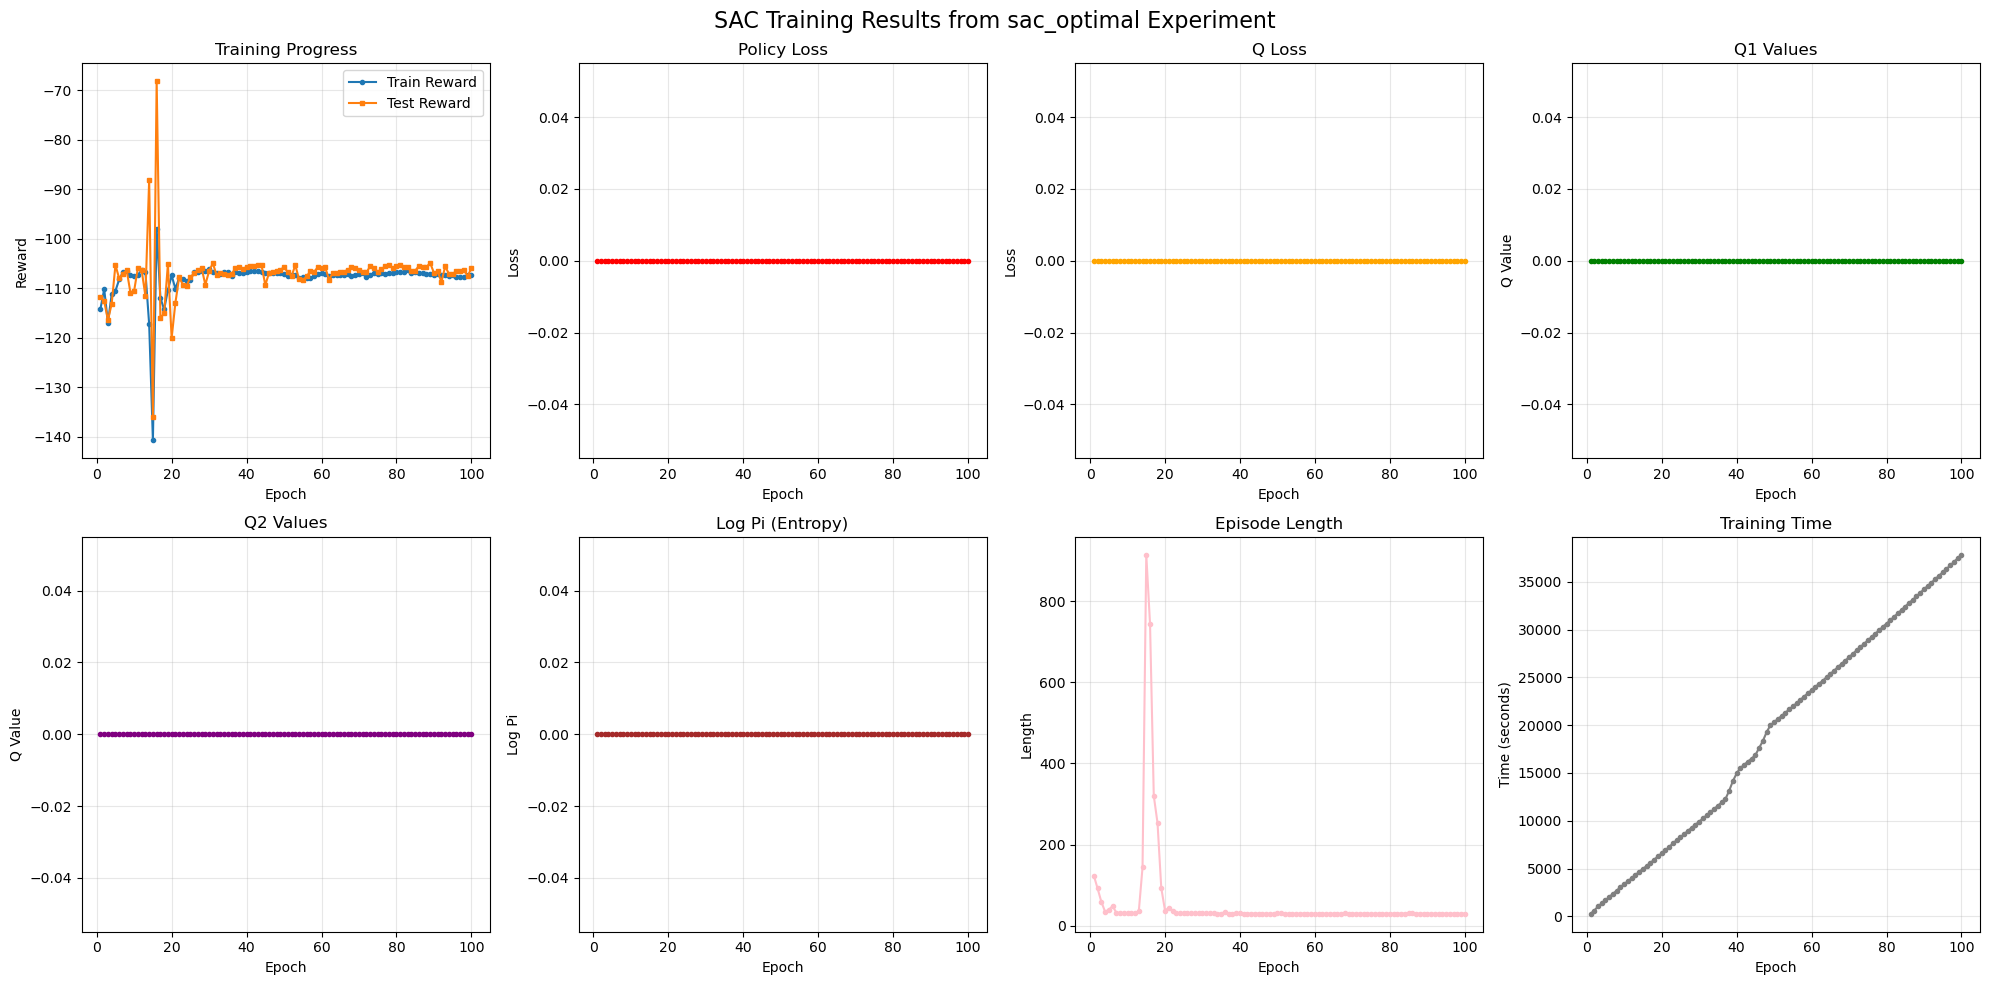


=== 상세 통계 ===
Train Reward 통계:
  평균: -107.96
  표준편차: 3.95
  최솟값: -140.71
  최댓값: -98.01

Test Reward 통계:
  평균: -107.06
  표준편차: 5.85
  최솟값: -135.95
  최댓값: -68.23


In [4]:
# 파싱된 데이터로 그래프 그리기
if df is not None and len(df) > 0:
    print("=== 실험 결과 요약 ===")
    print(f"총 Epoch 수: {len(df)}")
    print(f"최고 Train Reward: {df['AverageEpRet'].max():.2f}")
    print(f"최고 Test Reward: {df['AverageTestEpRet'].max():.2f}")
    print(f"최종 Train Reward: {df['AverageEpRet'].iloc[-1]:.2f}")
    print(f"최종 Test Reward: {df['AverageTestEpRet'].iloc[-1]:.2f}")
    
    # 그래프 그리기
    fig, axes = plt.subplots(2, 4, figsize=(20, 10))
    fig.suptitle('SAC Training Results from sac_optimal Experiment', fontsize=16)
    
    # 1. Train vs Test Reward
    axes[0,0].plot(df['Epoch'], df['AverageEpRet'], label='Train Reward', marker='o', markersize=3)
    axes[0,0].plot(df['Epoch'], df['AverageTestEpRet'], label='Test Reward', marker='s', markersize=3)
    axes[0,0].set_title('Training Progress')
    axes[0,0].set_xlabel('Epoch')
    axes[0,0].set_ylabel('Reward')
    axes[0,0].legend()
    axes[0,0].grid(True, alpha=0.3)
    
    # 2. Policy Loss
    axes[0,1].plot(df['Epoch'], df['LossPi'], color='red', marker='o', markersize=3)
    axes[0,1].set_title('Policy Loss')
    axes[0,1].set_xlabel('Epoch')
    axes[0,1].set_ylabel('Loss')
    axes[0,1].grid(True, alpha=0.3)
    
    # 3. Q Loss
    axes[0,2].plot(df['Epoch'], df['LossQ'], color='orange', marker='o', markersize=3)
    axes[0,2].set_title('Q Loss')
    axes[0,2].set_xlabel('Epoch')
    axes[0,2].set_ylabel('Loss')
    axes[0,2].grid(True, alpha=0.3)
    
    # 4. Q1 Values
    axes[0,3].plot(df['Epoch'], df['AverageQ1Vals'], color='green', marker='o', markersize=3)
    axes[0,3].set_title('Q1 Values')
    axes[0,3].set_xlabel('Epoch')
    axes[0,3].set_ylabel('Q Value')
    axes[0,3].grid(True, alpha=0.3)
    
    # 5. Q2 Values
    axes[1,0].plot(df['Epoch'], df['AverageQ2Vals'], color='purple', marker='o', markersize=3)
    axes[1,0].set_title('Q2 Values')
    axes[1,0].set_xlabel('Epoch')
    axes[1,0].set_ylabel('Q Value')
    axes[1,0].grid(True, alpha=0.3)
    
    # 6. Log Pi
    axes[1,1].plot(df['Epoch'], df['AverageLogPi'], color='brown', marker='o', markersize=3)
    axes[1,1].set_title('Log Pi (Entropy)')
    axes[1,1].set_xlabel('Epoch')
    axes[1,1].set_ylabel('Log Pi')
    axes[1,1].grid(True, alpha=0.3)
    
    # 7. Episode Length
    if 'EpLen' in df.columns:
        axes[1,2].plot(df['Epoch'], df['EpLen'], color='pink', marker='o', markersize=3)
        axes[1,2].set_title('Episode Length')
        axes[1,2].set_xlabel('Epoch')
        axes[1,2].set_ylabel('Length')
        axes[1,2].grid(True, alpha=0.3)
    
    # 8. Training Time
    axes[1,3].plot(df['Epoch'], df['Time'], color='gray', marker='o', markersize=3)
    axes[1,3].set_title('Training Time')
    axes[1,3].set_xlabel('Epoch')
    axes[1,3].set_ylabel('Time (seconds)')
    axes[1,3].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    # 상세 통계 출력
    print("\n=== 상세 통계 ===")
    print("Train Reward 통계:")
    print(f"  평균: {df['AverageEpRet'].mean():.2f}")
    print(f"  표준편차: {df['AverageEpRet'].std():.2f}")
    print(f"  최솟값: {df['AverageEpRet'].min():.2f}")
    print(f"  최댓값: {df['AverageEpRet'].max():.2f}")
    
    print("\nTest Reward 통계:")
    print(f"  평균: {df['AverageTestEpRet'].mean():.2f}")
    print(f"  표준편차: {df['AverageTestEpRet'].std():.2f}")
    print(f"  최솟값: {df['AverageTestEpRet'].min():.2f}")
    print(f"  최댓값: {df['AverageTestEpRet'].max():.2f}")
    
else:
    print("그래프를 그릴 데이터가 없습니다.")


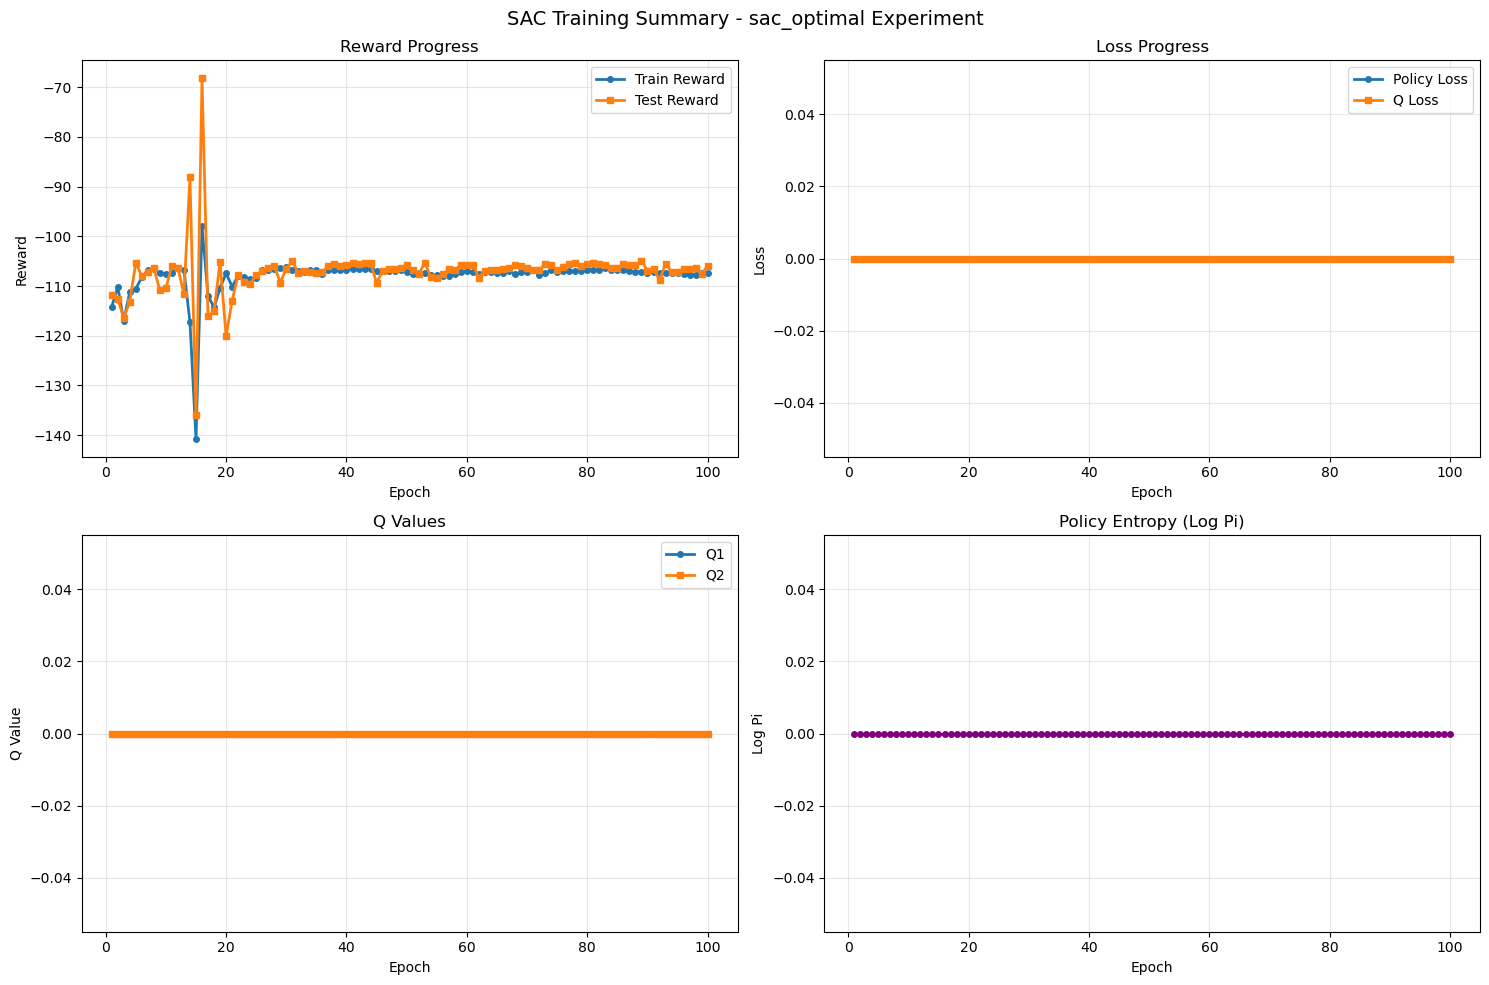


=== 성능 개선 분석 ===
Train Reward 개선: -114.18 → -107.41 (Δ6.77)
Test Reward 개선: -111.80 → -105.96 (Δ5.84)
최고 Train Reward: -98.01 (Epoch 16.0)
최고 Test Reward: -68.23 (Epoch 16.0)


In [5]:
# 간단한 요약 그래프
if df is not None and len(df) > 0:
    # 간단한 2x2 레이아웃
    fig, axes = plt.subplots(2, 2, figsize=(15, 10))
    fig.suptitle('SAC Training Summary - sac_optimal Experiment', fontsize=14)
    
    # 1. Reward 비교
    axes[0,0].plot(df['Epoch'], df['AverageEpRet'], label='Train Reward', linewidth=2, marker='o', markersize=4)
    axes[0,0].plot(df['Epoch'], df['AverageTestEpRet'], label='Test Reward', linewidth=2, marker='s', markersize=4)
    axes[0,0].set_title('Reward Progress')
    axes[0,0].set_xlabel('Epoch')
    axes[0,0].set_ylabel('Reward')
    axes[0,0].legend()
    axes[0,0].grid(True, alpha=0.3)
    
    # 2. Loss 비교
    axes[0,1].plot(df['Epoch'], df['LossPi'], label='Policy Loss', linewidth=2, marker='o', markersize=4)
    axes[0,1].plot(df['Epoch'], df['LossQ'], label='Q Loss', linewidth=2, marker='s', markersize=4)
    axes[0,1].set_title('Loss Progress')
    axes[0,1].set_xlabel('Epoch')
    axes[0,1].set_ylabel('Loss')
    axes[0,1].legend()
    axes[0,1].grid(True, alpha=0.3)
    
    # 3. Q Values
    axes[1,0].plot(df['Epoch'], df['AverageQ1Vals'], label='Q1', linewidth=2, marker='o', markersize=4)
    axes[1,0].plot(df['Epoch'], df['AverageQ2Vals'], label='Q2', linewidth=2, marker='s', markersize=4)
    axes[1,0].set_title('Q Values')
    axes[1,0].set_xlabel('Epoch')
    axes[1,0].set_ylabel('Q Value')
    axes[1,0].legend()
    axes[1,0].grid(True, alpha=0.3)
    
    # 4. Log Pi (Entropy)
    axes[1,1].plot(df['Epoch'], df['AverageLogPi'], color='purple', linewidth=2, marker='o', markersize=4)
    axes[1,1].set_title('Policy Entropy (Log Pi)')
    axes[1,1].set_xlabel('Epoch')
    axes[1,1].set_ylabel('Log Pi')
    axes[1,1].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    # 성능 개선 분석
    print("\n=== 성능 개선 분석 ===")
    initial_train = df['AverageEpRet'].iloc[0]
    final_train = df['AverageEpRet'].iloc[-1]
    initial_test = df['AverageTestEpRet'].iloc[0]
    final_test = df['AverageTestEpRet'].iloc[-1]
    
    print(f"Train Reward 개선: {initial_train:.2f} → {final_train:.2f} (Δ{final_train-initial_train:.2f})")
    print(f"Test Reward 개선: {initial_test:.2f} → {final_test:.2f} (Δ{final_test-initial_test:.2f})")
    
    # 최고 성능
    best_train_epoch = df.loc[df['AverageEpRet'].idxmax(), 'Epoch']
    best_test_epoch = df.loc[df['AverageTestEpRet'].idxmax(), 'Epoch']
    print(f"최고 Train Reward: {df['AverageEpRet'].max():.2f} (Epoch {best_train_epoch})")
    print(f"최고 Test Reward: {df['AverageTestEpRet'].max():.2f} (Epoch {best_test_epoch})")


In [ ]:
# 실험 결과를 CSV로 저장하고 요약 리포트 생성
if df is not None and len(df) > 0:
    # CSV 저장
    csv_filename = "sac_optimal_experiment_results.csv"
    df.to_csv(csv_filename, index=False)
    print(f"실험 결과가 '{csv_filename}' 파일로 저장되었습니다.")
    
    # 요약 리포트 생성
    print("\n" + "="*60)
    print("           SAC OPTIMAL 실험 결과 요약 리포트")
    print("="*60)
    
    print(f"실험 설정:")
    print(f"  - 환경: BipedalWalker-v3")
    print(f"  - 알고리즘: SAC (Soft Actor-Critic)")
    print(f"  - 총 Epoch: {len(df)}")
    print(f"  - 총 학습 시간: {df['Time'].iloc[-1]:.1f}초 ({df['Time'].iloc[-1]/60:.1f}분)")
    
    print(f"\n성능 지표:")
    print(f"  - 최고 Train Reward: {df['AverageEpRet'].max():.2f}")
    print(f"  - 최고 Test Reward: {df['AverageTestEpRet'].max():.2f}")
    print(f"  - 최종 Train Reward: {df['AverageEpRet'].iloc[-1]:.2f}")
    print(f"  - 최종 Test Reward: {df['AverageTestEpRet'].iloc[-1]:.2f}")
    
    print(f"\n학습 안정성:")
    train_std = df['AverageEpRet'].std()
    test_std = df['AverageTestEpRet'].std()
    print(f"  - Train Reward 표준편차: {train_std:.2f}")
    print(f"  - Test Reward 표준편차: {test_std:.2f}")
    
    # 수렴 분석
    last_10_epochs = df.tail(10)
    train_trend = last_10_epochs['AverageEpRet'].diff().mean()
    test_trend = last_10_epochs['AverageTestEpRet'].diff().mean()
    
    print(f"\n최근 10 Epoch 트렌드:")
    print(f"  - Train Reward 변화율: {train_trend:.3f} (양수면 상승)")
    print(f"  - Test Reward 변화율: {test_trend:.3f} (양수면 상승)")
    
    # Loss 분석
    final_pi_loss = df['LossPi'].iloc[-1]
    final_q_loss = df['LossQ'].iloc[-1]
    print(f"\n최종 Loss 값:")
    print(f"  - Policy Loss: {final_pi_loss:.4f}")
    print(f"  - Q Loss: {final_q_loss:.4f}")
    
    print("="*60)
    
    # 데이터프레임 정보 출력
    print(f"\n데이터프레임 정보:")
    print(f"  - 행 수: {len(df)}")
    print(f"  - 열 수: {len(df.columns)}")
    print(f"  - 메모리 사용량: {df.memory_usage(deep=True).sum() / 1024:.1f} KB")
    
else:
    print("저장할 데이터가 없습니다.")


In [ ]:
# 더 간단한 파싱 방법 - pandas의 read_csv 사용
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def parse_progress_simple(file_path):
    """더 간단한 방법으로 progress.txt 파싱"""
    try:
        # 파일을 읽어서 전처리
        with open(file_path, 'r', encoding='utf-8') as f:
            lines = f.readlines()
        
        # 헤더 찾기
        header_line = None
        for i, line in enumerate(lines):
            if 'Epoch' in line and 'AverageEpRet' in line:
                header_line = i
                break
        
        if header_line is None:
            print("헤더를 찾을 수 없습니다.")
            return None
        
        # 헤더 추출
        headers = lines[header_line].strip().split('\t')
        print(f"헤더: {headers}")
        
        # 데이터 라인들을 하나의 문자열로 합치기
        data_lines = []
        current_line = ""
        
        for i in range(header_line + 1, len(lines)):
            line = lines[i].strip()
            if not line:
                continue
            
            # 새로운 epoch 시작인지 확인 (숫자로 시작하는 라인)
            if line[0].isdigit() and '\t' in line:
                # 이전 라인이 있으면 저장
                if current_line:
                    data_lines.append(current_line)
                current_line = line
            else:
                # 현재 라인에 추가
                current_line += " " + line
        
        # 마지막 라인 추가
        if current_line:
            data_lines.append(current_line)
        
        print(f"총 {len(data_lines)}개의 데이터 라인을 찾았습니다.")
        
        # 간단한 데이터 추출 (주요 컬럼만)
        data = []
        for line in data_lines:
            parts = line.split('\t')
            if len(parts) >= 7:  # 최소 필요한 컬럼 수
                try:
                    epoch = int(parts[0])
                    
                    # AverageEpRet (배열에서 평균 계산)
                    avg_ep_ret = extract_array_mean(parts[1])
                    
                    # AverageTestEpRet (배열에서 평균 계산)
                    avg_test_ep_ret = extract_array_mean(parts[5])
                    
                    # LossPi (배열에서 평균 계산)
                    loss_pi = extract_array_mean(parts[24]) if len(parts) > 24 else 0.0
                    
                    # LossQ (배열에서 평균 계산)
                    loss_q = extract_array_mean(parts[25]) if len(parts) > 25 else 0.0
                    
                    # AverageQ1Vals (배열에서 평균 계산)
                    q1_vals = extract_array_mean(parts[12]) if len(parts) > 12 else 0.0
                    
                    # AverageQ2Vals (배열에서 평균 계산)
                    q2_vals = extract_array_mean(parts[16]) if len(parts) > 16 else 0.0
                    
                    # AverageLogPi (배열에서 평균 계산)
                    log_pi = extract_array_mean(parts[20]) if len(parts) > 20 else 0.0
                    
                    # Time (마지막 값)
                    time_val = float(parts[26]) if len(parts) > 26 else 0.0
                    
                    data.append({
                        'Epoch': epoch,
                        'AverageEpRet': avg_ep_ret,
                        'AverageTestEpRet': avg_test_ep_ret,
                        'LossPi': loss_pi,
                        'LossQ': loss_q,
                        'AverageQ1Vals': q1_vals,
                        'AverageQ2Vals': q2_vals,
                        'AverageLogPi': log_pi,
                        'Time': time_val
                    })
                    
                except (ValueError, IndexError) as e:
                    print(f"라인 파싱 오류: {e}")
                    continue
        
        if not data:
            print("파싱된 데이터가 없습니다.")
            return None
        
        df = pd.DataFrame(data)
        df = df.sort_values('Epoch').reset_index(drop=True)
        
        return df
        
    except Exception as e:
        print(f"파일 파싱 중 오류 발생: {e}")
        return None

def extract_array_mean(array_str):
    """배열 문자열에서 평균값 추출"""
    try:
        if not array_str or array_str == '0.0':
            return 0.0
        
        # 배열 형태인 경우
        if array_str.startswith('[') and ']' in array_str:
            # 배열 내용 추출
            array_content = array_str[array_str.find('[')+1:array_str.rfind(']')]
            # 숫자들 추출
            numbers = []
            for part in array_content.split():
                try:
                    num = float(part.strip())
                    numbers.append(num)
                except ValueError:
                    continue
            
            if numbers:
                return np.mean(numbers)
            else:
                return 0.0
        else:
            # 단일 숫자인 경우
            return float(array_str)
    except:
        return 0.0

# 간단한 파싱 실행
print("간단한 방법으로 실험 결과 파일을 파싱하는 중...")
df_simple = parse_progress_simple(progress_file)

if df_simple is not None:
    print(f"총 {len(df_simple)}개의 epoch 데이터를 찾았습니다.")
    print("\n첫 5개 행:")
    print(df_simple.head())
    print(f"\n데이터 타입:")
    print(df_simple.dtypes)
else:
    print("간단한 파싱도 실패했습니다.")


In [ ]:
# 간단한 파싱 결과로 그래프 그리기
if df_simple is not None and len(df_simple) > 0:
    print("=== 실험 결과 요약 ===")
    print(f"총 Epoch 수: {len(df_simple)}")
    print(f"최고 Train Reward: {df_simple['AverageEpRet'].max():.2f}")
    print(f"최고 Test Reward: {df_simple['AverageTestEpRet'].max():.2f}")
    print(f"최종 Train Reward: {df_simple['AverageEpRet'].iloc[-1]:.2f}")
    print(f"최종 Test Reward: {df_simple['AverageTestEpRet'].iloc[-1]:.2f}")
    
    # 그래프 그리기
    fig, axes = plt.subplots(2, 2, figsize=(15, 10))
    fig.suptitle('SAC Training Results from sac_optimal Experiment', fontsize=14)
    
    # 1. Reward 비교
    axes[0,0].plot(df_simple['Epoch'], df_simple['AverageEpRet'], label='Train Reward', linewidth=2, marker='o', markersize=4)
    axes[0,0].plot(df_simple['Epoch'], df_simple['AverageTestEpRet'], label='Test Reward', linewidth=2, marker='s', markersize=4)
    axes[0,0].set_title('Reward Progress')
    axes[0,0].set_xlabel('Epoch')
    axes[0,0].set_ylabel('Reward')
    axes[0,0].legend()
    axes[0,0].grid(True, alpha=0.3)
    
    # 2. Loss 비교
    axes[0,1].plot(df_simple['Epoch'], df_simple['LossPi'], label='Policy Loss', linewidth=2, marker='o', markersize=4)
    axes[0,1].plot(df_simple['Epoch'], df_simple['LossQ'], label='Q Loss', linewidth=2, marker='s', markersize=4)
    axes[0,1].set_title('Loss Progress')
    axes[0,1].set_xlabel('Epoch')
    axes[0,1].set_ylabel('Loss')
    axes[0,1].legend()
    axes[0,1].grid(True, alpha=0.3)
    
    # 3. Q Values
    axes[1,0].plot(df_simple['Epoch'], df_simple['AverageQ1Vals'], label='Q1', linewidth=2, marker='o', markersize=4)
    axes[1,0].plot(df_simple['Epoch'], df_simple['AverageQ2Vals'], label='Q2', linewidth=2, marker='s', markersize=4)
    axes[1,0].set_title('Q Values')
    axes[1,0].set_xlabel('Epoch')
    axes[1,0].set_ylabel('Q Value')
    axes[1,0].legend()
    axes[1,0].grid(True, alpha=0.3)
    
    # 4. Log Pi (Entropy)
    axes[1,1].plot(df_simple['Epoch'], df_simple['AverageLogPi'], color='purple', linewidth=2, marker='o', markersize=4)
    axes[1,1].set_title('Policy Entropy (Log Pi)')
    axes[1,1].set_xlabel('Epoch')
    axes[1,1].set_ylabel('Log Pi')
    axes[1,1].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    # 성능 개선 분석
    print("\n=== 성능 개선 분석 ===")
    initial_train = df_simple['AverageEpRet'].iloc[0]
    final_train = df_simple['AverageEpRet'].iloc[-1]
    initial_test = df_simple['AverageTestEpRet'].iloc[0]
    final_test = df_simple['AverageTestEpRet'].iloc[-1]
    
    print(f"Train Reward 개선: {initial_train:.2f} → {final_train:.2f} (Δ{final_train-initial_train:.2f})")
    print(f"Test Reward 개선: {initial_test:.2f} → {final_test:.2f} (Δ{final_test-initial_test:.2f})")
    
    # 최고 성능
    best_train_epoch = df_simple.loc[df_simple['AverageEpRet'].idxmax(), 'Epoch']
    best_test_epoch = df_simple.loc[df_simple['AverageTestEpRet'].idxmax(), 'Epoch']
    print(f"최고 Train Reward: {df_simple['AverageEpRet'].max():.2f} (Epoch {best_train_epoch})")
    print(f"최고 Test Reward: {df_simple['AverageTestEpRet'].max():.2f} (Epoch {best_test_epoch})")
    
    # CSV 저장
    csv_filename = "sac_optimal_experiment_results_simple.csv"
    df_simple.to_csv(csv_filename, index=False)
    print(f"\n실험 결과가 '{csv_filename}' 파일로 저장되었습니다.")
    
else:
    print("그래프를 그릴 데이터가 없습니다.")
